# BUSINESS UNDERTANDING
#### >Churn adalah metrik bisnis yang mengukur jumlah pelanggan yang berhenti menggunakan produk atau layanan

##### >> Telco adalah perusahaan telekomunikasi yang menyediakan layanan seperti internet, telepon, dan layanan tambahan lainnya. Dalam project ini, dataset digunakan untuk menganalisis faktor-faktor yang berkaitan dengan customer churn pada perusahaan telco.

Tujuan project ini adalah menganaisis faktor yang mempengaruhi customer churn pada perusahaan telco dan membuat model sederhana untuk mengidentifikasi pelanggan berisiko churn

## Pertanyaan bisnisnya

1. Berapa churn rate customer?
2. Customer seperti apa yang seting churn
3. Faktor apa yang paling berhubungan dengan churn
4. segment mana yang harus diprioritaskan untuk retention



In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


# Load Dataset

In [12]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


# EDA (Exploratory Data Analysis)

In [7]:
# ukuran data(baris, kolom)
df.shape

(7043, 21)

In [8]:
#ini lebih jelas (baris, kolom) dan tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## DATA UNDERSTANDING

#### 1. apakah ada missing value?
#### 2. apakah ada duplikasi?
#### 3. jumlah kategori di tiap kolom
#### 4. distibusi target churn

In [14]:
# ringkasan deskriptif numerik
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


##### >>> tenure adalah lama masa berlangganan
##### >>> rata rata 0.162147 di senior citizen(orang tua) artinya adalah 16.2 % adalah orang tua, 83.8% bukan orang tua





In [15]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [24]:
# Mencari nilai kosong dan duplikat

print("Missing Values:")
print(df.isna().sum())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [25]:
# Mencari nilai kosong dan duplikat

print("Duplicate Values:")
print(df.duplicated().sum())

Duplicate Values:
0


In [27]:
df['Churn'].value_counts()


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [29]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

# Target Variable: Churn 


> berdasarkan data yang ada 73.5% tidak berhenti berlangganan

> sedangkan 26.5% berhenti berlangganan atau churn. ini yang menjadi perhatian selanjutnya

In [30]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

> ada yang aneh pada salah satu kolom di dataset ini, yaitu "**TotalCharges**" karena dia bentuknya object dan bukan angka padahal harusnya isinya angka karena itu adalah nilai dari total bayar

In [35]:
df['TotalCharges'].dtype

dtype('O')

In [38]:
df['TotalCharges'].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

> Disini dari **"TotalCharges"** datanya angka bukan txt atau char
> jadi harus di ubah menjadi angka

### Mengubah tipe data dari TotalCharges

In [66]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

> errors='coerse' adalah kalau ada nilai yang gagal diubah jadi angka, ubah menjadi NaN / missing value.



In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [47]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [48]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


#### Melihat data kosong di TotalCharges

In [57]:
print("Missing Value TotalCharges")
print(df['TotalCharges'].isna().sum())

Missing Value TotalCharges
11


#### Menhapus atau drop data dari TotalCharges karena cuma sedikit

In [63]:
df = df.dropna(subset=['TotalCharges'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

> **subset** artinya mengambil kolom tertentu

> formatnya itu subset=['kolom1', 'kolom2']

In [67]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Setelah melakukan EDA tahap pertama

#### 1. berapa banyak customer yang churn?

In [75]:
print("Data per customer:")
print(df['Churn'].value_counts())

print("\nPersentase Data:")
print(df['Churn'].value_counts(normalize= True) * 100 )

Data per customer:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Persentase Data:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


## Visualiasi Customer Churn

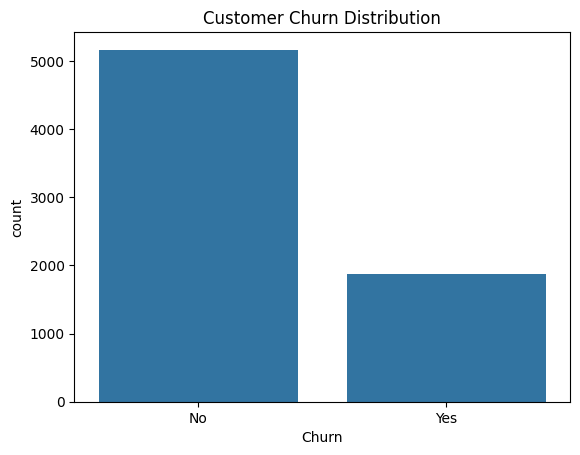

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

## Mencari kolom mana yang sangat berkaitan dengan orang tidak mau berlangganan lagi atau churn

> hue adalah pembeda warnanya, pada kasus ini menjadi pembeda dari kolom dependents

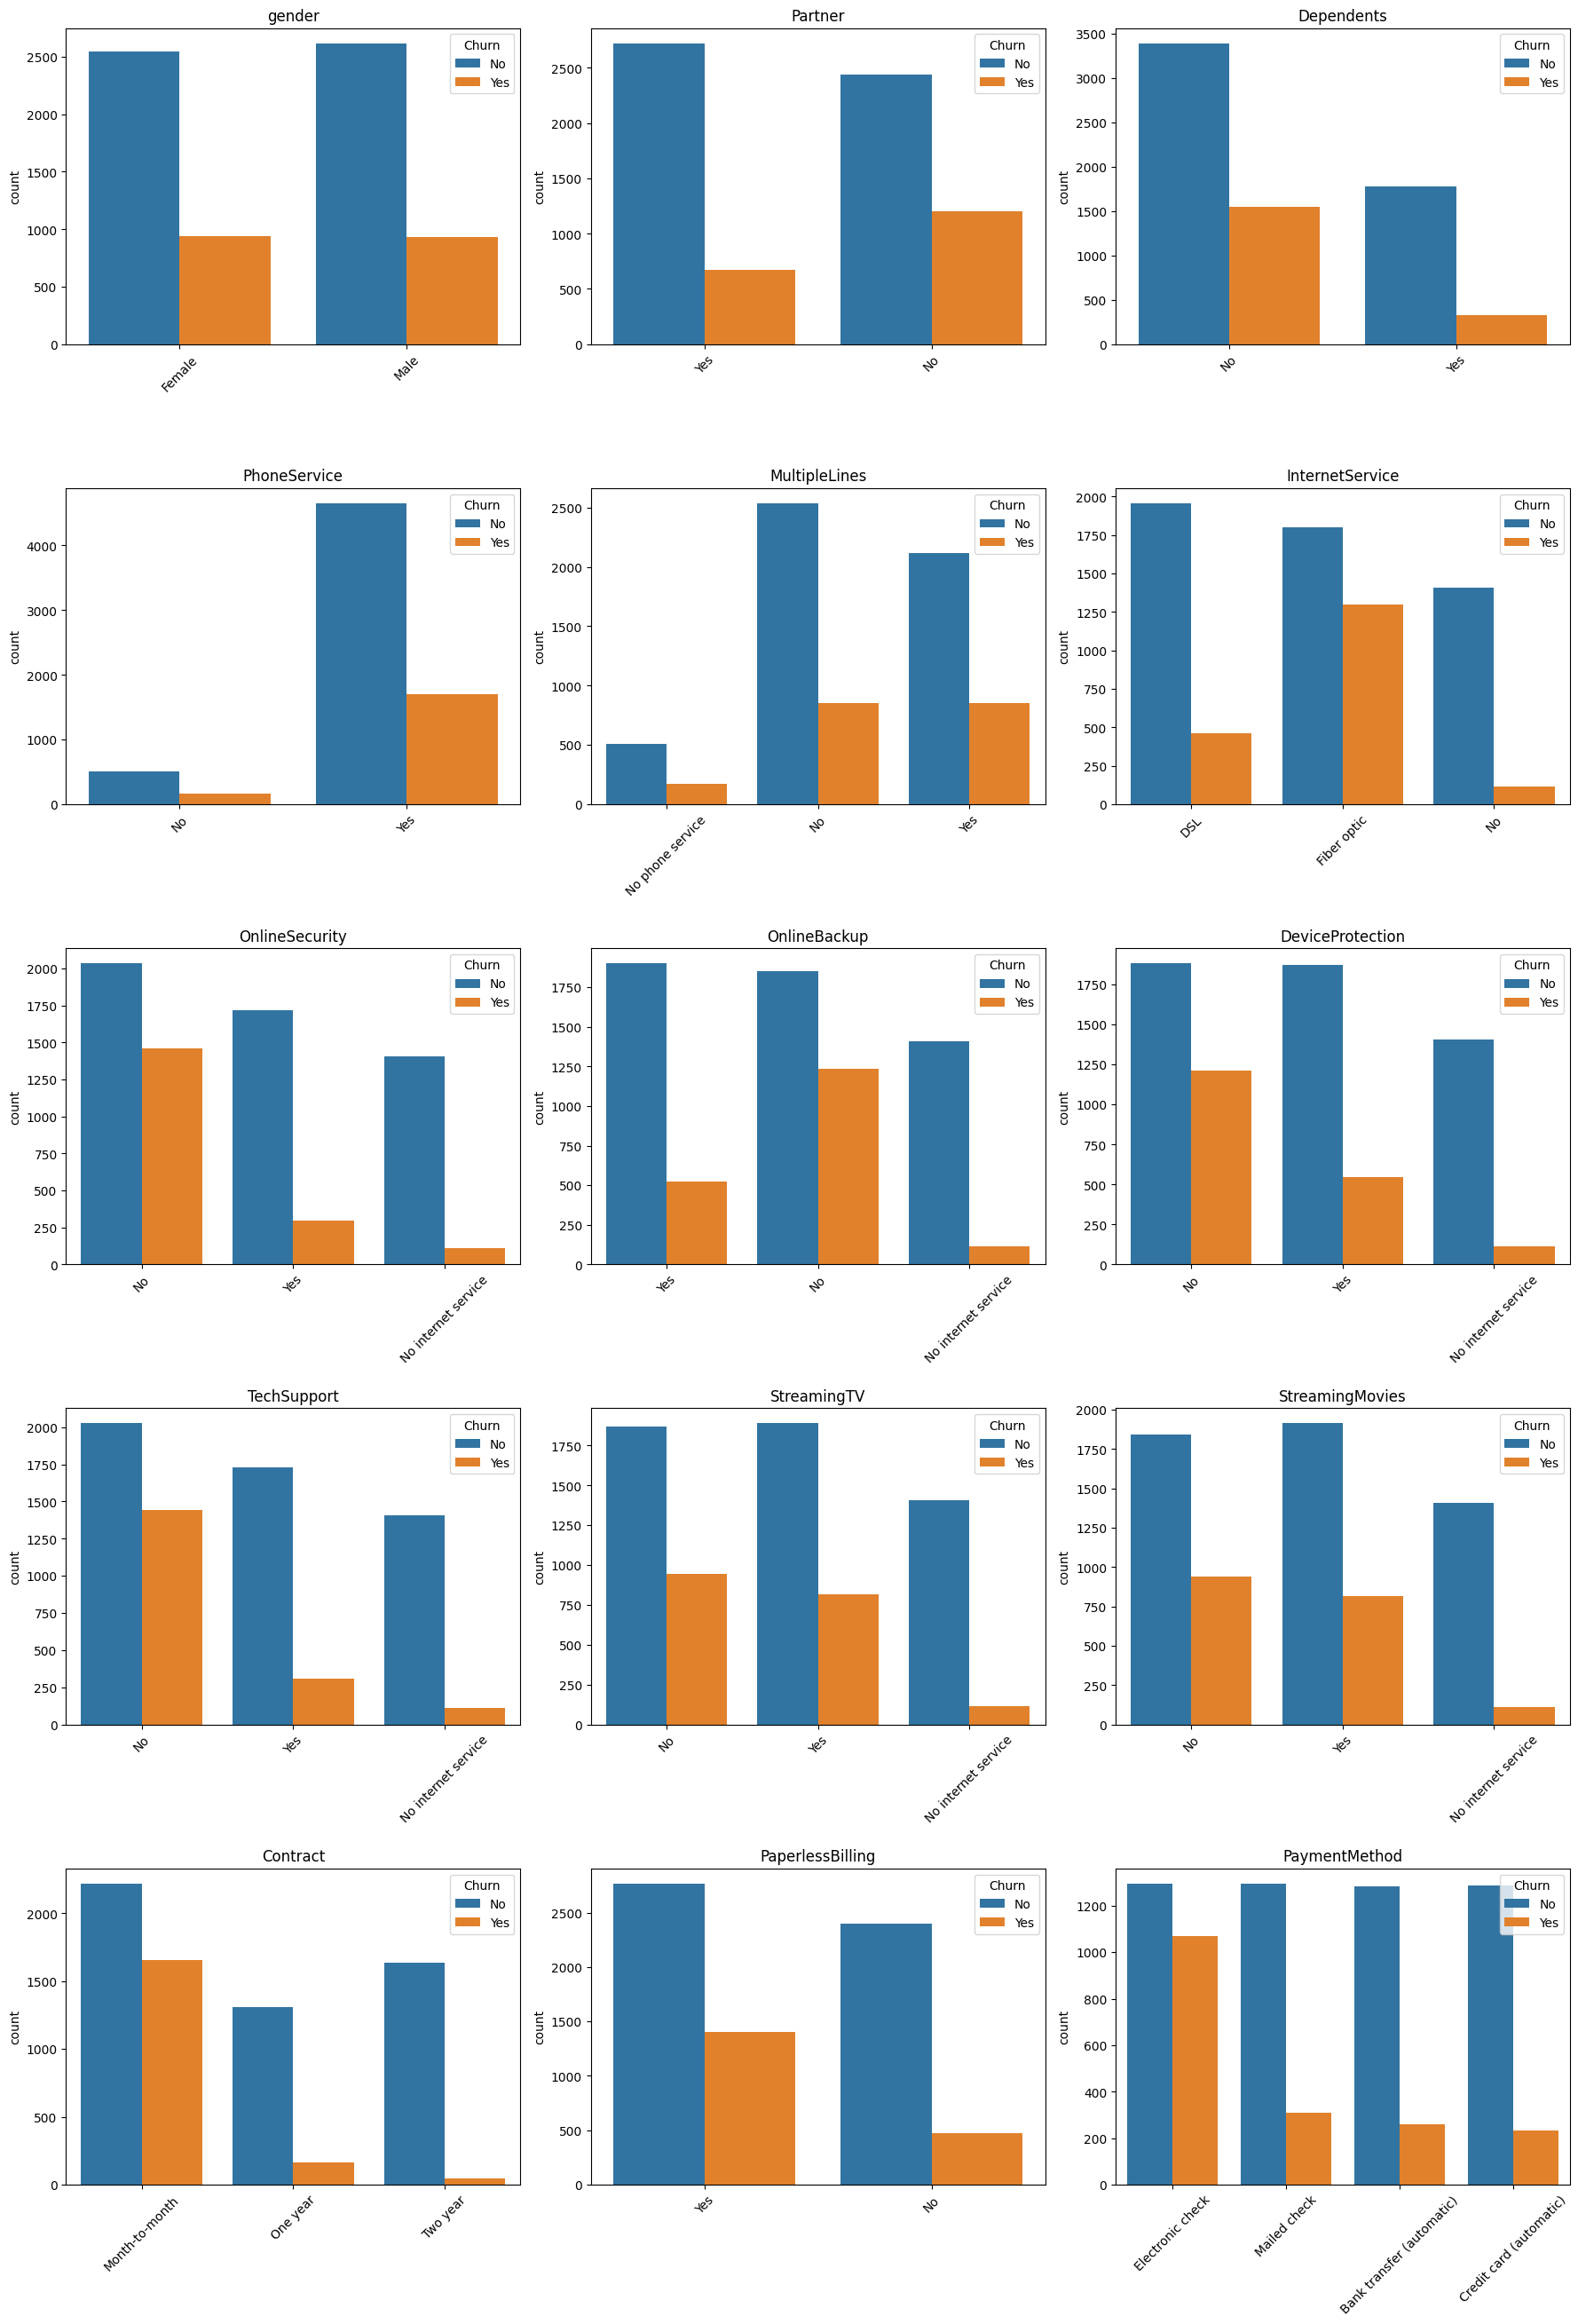

In [107]:
cat_cols = df.select_dtypes(include='object').columns.tolist()

cat_cols.remove('customerID')
cat_cols.remove('Churn')

n = len(cat_cols)
fig, axes = plt.subplots(nrows=(n//3)+1, ncols=3, figsize=(18, n*2))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Churn', ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
    
plt.tight_layout()
plt.show()

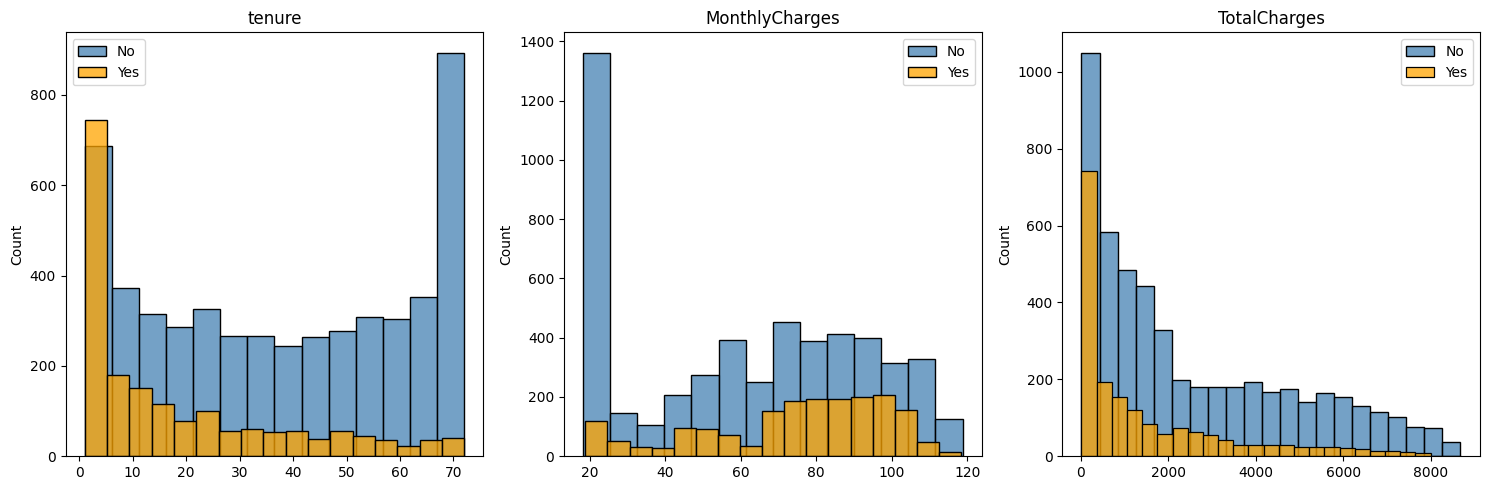

In [124]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
num_cols.remove('SeniorCitizen')

fig, axes = plt.subplots(nrows=1, ncols=len(num_cols), figsize=(15, 5))

for i, col in enumerate(num_cols):
    # gambar No dulu (besar, jadi lapisan bawah)
    sns.histplot(data=df[df['Churn']=='No'], x=col, 
                 ax=axes[i], color='steelblue', label='No')
    
    # gambar Yes di atasnya (kecil, jadi lapisan atas)
    sns.histplot(data=df[df['Churn']=='Yes'], x=col, 
                 ax=axes[i], color='orange', label='Yes')
    
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].legend()


for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
    
plt.tight_layout()
plt.show()

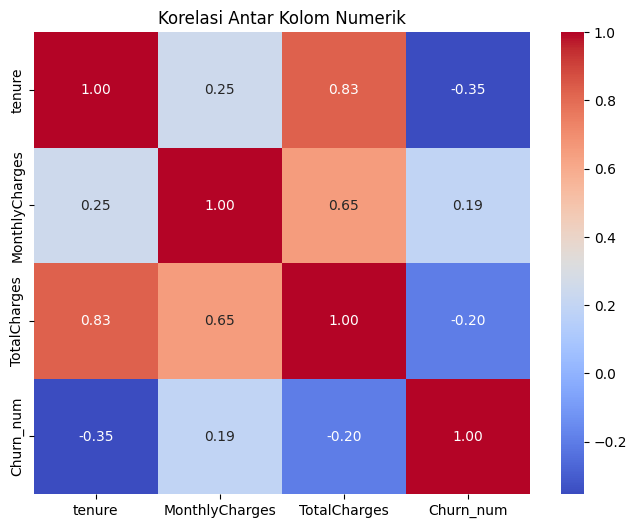

In [135]:
# heatmap

df['Churn_num'] = df['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(8, 6))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_num']].corr(),
           annot=True, cmap='coolwarm',
           fmt='.2f')
plt.title('Korelasi Antar Kolom Numerik')
plt.show()


In [138]:
df = df.drop(columns=['customerID'])

### Encode target

In [139]:
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

In [140]:
df = pd.get_dummies(df, drop_first=True)

> drop_first=True itu misalnya ada female dan male
> female 1 dan male 0 maka akan di drop 1 kolom karena dari encodenya sudah di ketahui bahwa 1 female dan 0 male

## Pemisahan data untuk training

In [165]:
X = df.drop(columns=['Churn', 'Churn_num'])
y = df['Churn']
feature_names = X.columns.tolist()  

In [170]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Pakai model yang paling simple dulu yaitu Logistic Regresion karena ini itu klasifikasi bentuknya adalah pilihan bukan angka

In [171]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=5000, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1033
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.75      1407



### Penjelasan dalam analogi maling
> precision adalah misal ada maling 100 berhasil nangkap 90 jadi 90% presisi

> recal dari yang 90 maling ketanggep ternyata ada yang kabur 10 maling jadinya 90% recall

> f1 adalah nilai dari gabungan presisi dan recal

> support adalah maling itu sendiri

## Model RandomForest

In [172]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(class_weight='balanced', random_state=42)
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))


              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1033
           1       0.63      0.45      0.53       374

    accuracy                           0.78      1407
   macro avg       0.73      0.68      0.69      1407
weighted avg       0.77      0.78      0.77      1407



## Model XGB

In [173]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(scale_pos_weight=3, random_state=42)
model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))


              precision    recall  f1-score   support

           0       0.86      0.76      0.81      1033
           1       0.50      0.67      0.58       374

    accuracy                           0.74      1407
   macro avg       0.68      0.72      0.69      1407
weighted avg       0.77      0.74      0.75      1407



## Feature Importance
> Kolom mana yang paling berpengaruh terhadap model pediksi

### Model LR

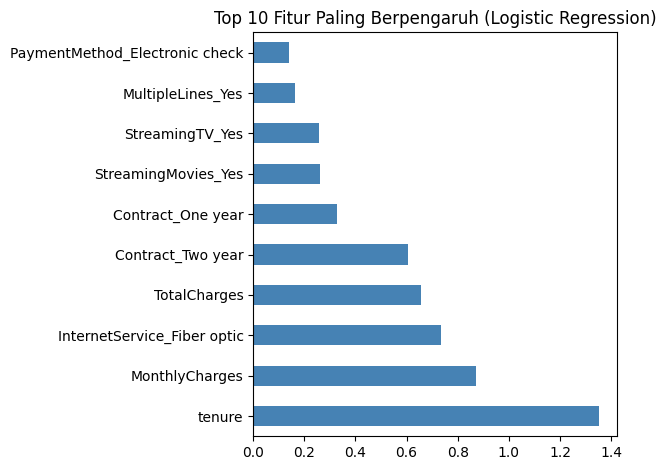

()

In [175]:
coef = pd.Series(
    np.abs(model.coef_[0]),
    index=feature_names
)

coef.nlargest(10).plot(kind='barh', color='steelblue')
plt.title('Top 10 Fitur Paling Berpengaruh (Logistic Regression)')
plt.tight_layout()
plt.show()
()


### Model RF

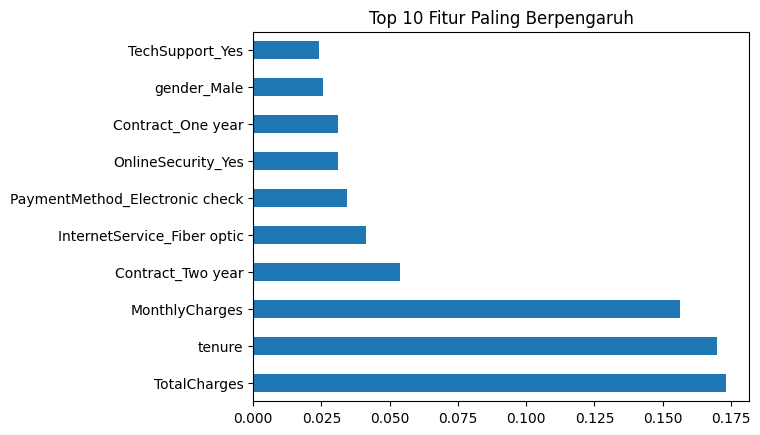

In [177]:
import pandas as pd
import matplotlib.pyplot as plt

feat_importance = pd.Series(model_rf.feature_importances_, 
                            index=feature_names)

feat_importance.nlargest(10).plot(kind='barh')
plt.title('Top 10 Fitur Paling Berpengaruh')
plt.show()


### Model XGB

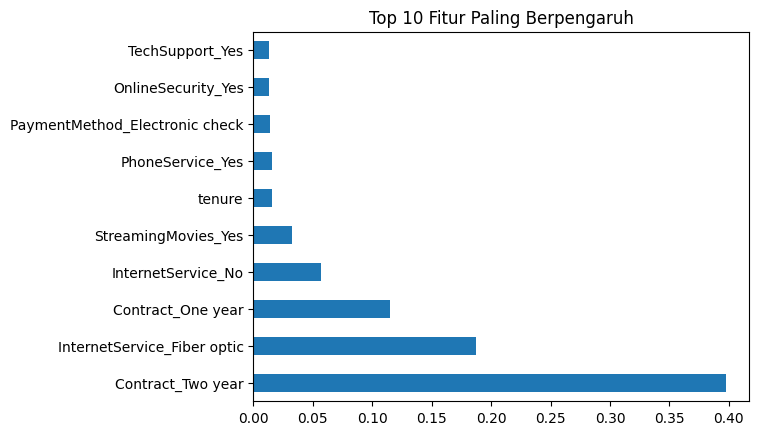

In [178]:
import pandas as pd
import matplotlib.pyplot as plt

feat_importance = pd.Series(model_xgb.feature_importances_, 
                            index=feature_names)

feat_importance.nlargest(10).plot(kind='barh')
plt.title('Top 10 Fitur Paling Berpengaruh')
plt.show()


# Kesimpulan


**Jawaban Bisnis**

1. **Berapa churn rate customer?**  
   Dari 7.032 customer setelah data cleaning, ada **1.869 customer churn** dan **5.163 tidak churn**.  
   Jadi churn rate-nya adalah **26,58%**. Artinya sekitar **1 dari 4 customer berhenti berlangganan**.

2. **Customer seperti apa yang sering churn?**  
   Customer yang paling sering churn cenderung punya karakteristik:
   - **tenure** rendah, terutama customer baru
   - kontrak **month-to-month**
   - menggunakan **Fiber optic**
   - membayar dengan **Electronic check**
   - menggunakan **Paperless Billing**
   - tidak punya layanan tambahan seperti **OnlineSecurity**, **TechSupport**, **OnlineBackup**, atau **DeviceProtection**
   - tidak punya partner/dependents

3. **Faktor apa yang paling berhubungan dengan churn?**  
   Dari korelasi numerik:
   - `tenure` punya hubungan negatif dengan churn: **-0.35**  
     Semakin lama customer berlangganan, semakin kecil kemungkinan churn.
   - `MonthlyCharges` punya hubungan positif: **0.19**  
     Semakin tinggi tagihan bulanan, churn cenderung meningkat.
   - `TotalCharges` negatif: **-0.20**, kemungkinan karena customer dengan total charge tinggi biasanya sudah lama berlangganan.

   Dari feature importance model, faktor yang sering muncul penting adalah:
   - `tenure`
   - `MonthlyCharges`
   - `TotalCharges`
   - `Contract`
   - `InternetService_Fiber optic`
   - `PaymentMethod_Electronic check`
   - `OnlineSecurity`
   - `TechSupport`

4. **Segment mana yang harus diprioritaskan untuk retention?**  
   Prioritas utama retention adalah customer dengan kombinasi risiko tinggi:

   **Customer baru + kontrak month-to-month + Fiber optic + MonthlyCharges tinggi + Electronic check + tidak punya OnlineSecurity/TechSupport.**

   Segment ini penting karena mereka punya peluang churn tinggi dan masih bisa dicegah dengan strategi retention seperti diskon awal, bundling layanan security/support, edukasi benefit paket, atau penawaran pindah ke kontrak tahunan.

Tambahan penting: karena tujuan bisnisnya adalah mendeteksi customer yang berpotensi churn, model **Logistic Regression** cukup cocok sebagai baseline karena recall churn-nya paling tinggi, yaitu **0.79**. Artinya model ini lebih baik dalam menangkap customer churn dibanding Random Forest dan XGBoost pada hasil analisis.